# 00 · Summary: North Atlantic variability and UK/Ireland extremes in two EERIE models

**Start here.** This notebook tells the whole story in seven figures and five tables. Each section
points to the notebook that has the full analysis, the method and the limitations.

## The question

> How do high-resolution coupled Earth-system models represent the winter North Atlantic
> Oscillation (NAO) and extremes over the UK and Ireland, and do they reproduce the link between
> the two?

Two further questions: do the conclusions depend on model resolution and on internal
variability, and is the simulated NAO sensitive to small-scale sea-surface temperature?

## The chain of reasoning

```
mean winter circulation  ->  NAO (pattern, strength)  ->  regional extremes  ->  NAO-to-extremes link
     notebook 03                   notebook 04               notebook 05            notebook 06

weather behind the extremes: notebook 09
how far to trust it: resolution (notebook 08), identical runs (notebooks 07 and 08)
```

A model can only be trusted on the last step if the earlier ones are credible, so each step is
checked against a reference before moving on.

## The data

| | What | Period |
|---|---|---|
| **ICON-ESM-ER**, **IFS-FESOM2-SR** | two EERIE coupled models with eddy-rich oceans, historical run, one member each | 1950–2014 monthly, 1985–2014 daily |
| **ERA5** | reanalysis reference for pressure, temperature and mean precipitation | 1950–2014 monthly |
| **E-OBS** | station-based gridded dataset, land only; reference for extremes | 1985–2014 daily |
| **ERA5 daily** | second reference for extremes | 1985–2014 daily |
| **IFS atmosphere-only ensembles** | paired experiments with observed and with filtered sea-surface temperature, ten members each | 1980–2023 monthly |
| **IFS atmosphere-only, 9 km and 28 km** | same model and SST at two resolutions; 1 and 3 members | 1985–2014 daily (28 km: winter) |

All data are public. Everything is exploratory: two models with one member each can show what is
*consistent across the two models examined*, not what is robust.

## How to read this notebook

Dark grey is ERA5, light grey is E-OBS, blue is ICON-ESM-ER, orange is IFS-FESOM2-SR.
In difference maps, grey means no difference. Every code cell has a note above it; every figure
has a caption. Technical terms are explained in the "Background" section of each detailed notebook.

**What this cell does.** Loads the project code and the small result tables saved by the detailed
notebooks.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
from eerie_uk import climatology as clim, extremes as ex, nao, plotting, regions, relationships as rel, store

pd.set_option('display.width', 220, 'display.float_format', '{:.2f}'.format)
NAME = plotting.SOURCE_LABELS
MODELS = ['icon-esm-er', 'ifs-fesom2-sr']
REFS = ['e-obs', 'era5']

## 1. Where: three nested domains

**What this cell does.** Draws the three domains: the North Atlantic (for the NAO), north-west
Europe (for temperature, rainfall and extremes) and the headline region, UK and Ireland.

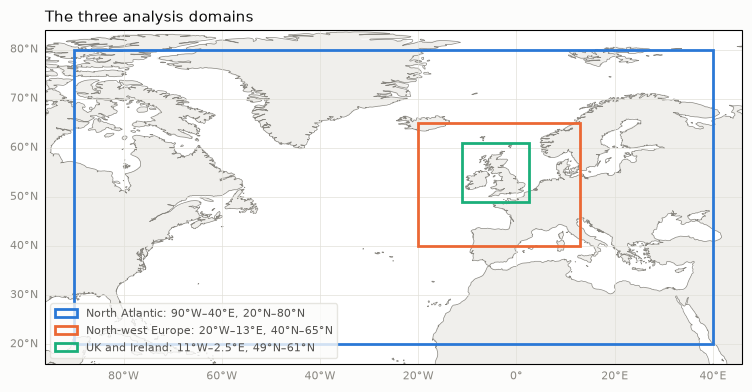

In [2]:
plotting.plot_boxes({name: regions.BOXES[name] for name in regions.DOMAINS}, regions.LABELS, title='The three analysis domains');

**Figure 1.** Large-scale circulation, European response, regional extremes. Details: notebook 02.

## 2. Is the mean winter circulation credible? (notebook 03)

**What this cell does.** Maps each model's average winter sea-level pressure minus ERA5's, 1985–2014.

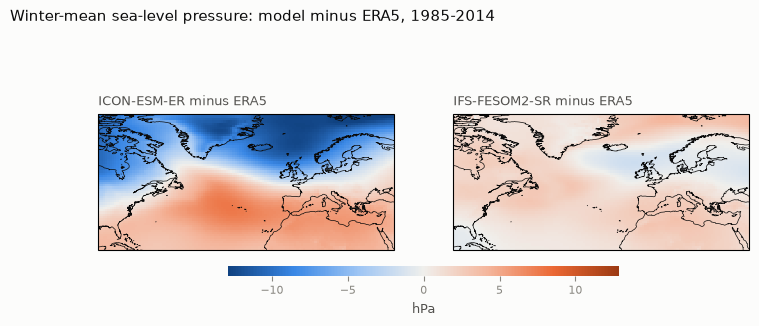

In [3]:
psl = {s: store.load(s, 'mon', 'psl', 'north_atlantic') for s in ['era5'] + MODELS}
mean_winter = {s: clim.climatology(clim.period(psl[s], 1985, 2014), 'DJF') for s in psl}
plotting.plot_field_panels({f'{NAME[m]} minus ERA5': mean_winter[m] - mean_winter['era5'] for m in MODELS},
                           units='hPa', diverging=True, title='Winter-mean sea-level pressure: model minus ERA5, 1985-2014');

**Figure 2.** Orange: pressure too high; blue: too low. **IFS-FESOM2-SR is close to ERA5**
(typical difference 1.8 hPa). **ICON-ESM-ER has a strong north–south dipole bias**: pressure up to
14 hPa too low in the north and up to 8 hPa too high in the subtropics, which means westerly winds
that are too strong on average. ICON-ESM-ER is also about 30% too wet in winter over north-west
Europe, and both models are about 0.8 °C too cold.

## 3. Is the NAO realistic? (notebook 04)

**What this cell does.** Computes the leading pattern of winter pressure variability (the NAO) for
ERA5 and both models over 64 winters, 1951–2014, and maps it.

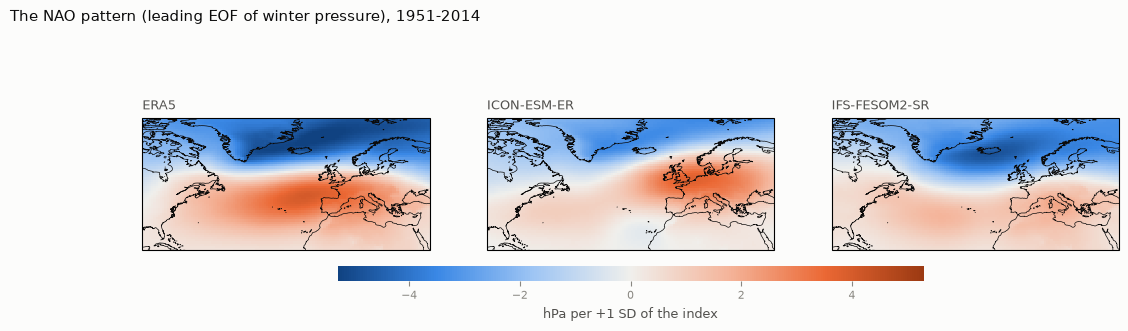

In [4]:
winters = {s: nao.winter_anomalies(psl[s]) for s in psl}
eofs = {s: nao.leading_eof(winters[s]) for s in psl}
plotting.plot_field_panels({NAME[s]: eofs[s].pattern for s in psl}, units='hPa per +1 SD of the index', diverging=True,
                           title='The NAO pattern (leading EOF of winter pressure), 1951-2014');

**Figure 3.** Blue: lower pressure in a positive-NAO winter; orange: higher. ERA5 shows the
textbook pattern. IFS-FESOM2-SR is recognisably the same, with a weak southern centre displaced
towards the Mediterranean. ICON-ESM-ER's southern centre sits over the North Sea: its leading
pattern is a mixture and not a clean NAO.

**What this cell does.** The key NAO numbers in one table: variance explained, similarity to the
ERA5 pattern, strength of the NAO measured along the ERA5 pattern, and the model's mean-pressure
bias expressed as an NAO state.

In [5]:
rows = []
for s in psl:
    projected = nao.project(winters[s], eofs['era5'].vector)
    bias = nao.project_map(clim.climatology(psl[s], 'DJF') - clim.climatology(psl['era5'], 'DJF'), eofs['era5'].vector) / eofs['era5'].amplitude
    rows.append({'': NAME[s], 'variance explained %': 100 * eofs[s].explained[0],
                 'pattern correlation with ERA5': clim.pattern_stats(eofs[s].pattern, eofs['era5'].pattern)['pattern correlation'],
                 'NAO strength relative to ERA5': float(projected.std(ddof=1)) / eofs['era5'].amplitude,
                 'mean-state bias as an NAO anomaly (SD)': bias})
pd.DataFrame(rows).set_index('')

,variance explained %,pattern correlation with ERA5,NAO strength relative to ERA5,mean-state bias as an NAO anomaly (SD)
,,,,
ERA5,47.38,1.00,1.00,0.00
ICON-ESM-ER,29.17,0.75,0.59,2.33
IFS-FESOM2-SR,34.78,0.87,0.71,0.51


**Reading the table.** Both models have a **weaker NAO than ERA5** (59% and 71% of its strength).
ICON-ESM-ER's *average* winter resembles a +2.3 SD positive-NAO winter of the real world.
Notebook 07 adds an important caution: ten runs of one atmosphere model give NAO strengths anywhere
from 0.70 to 1.00, so a single member's 0.71 may be partly chance; 0.59 lies below that whole range.

## 4. Are the extremes realistic? (notebook 05)

**What this cell does.** Shows the headline numbers for UK and Ireland (land average, 1985–2014):
the wettest day of the year (RX1day), the rain on very wet days (R95p) and the hottest day of the
year (TXx), for the reference data and both models.

In [6]:
regional = pd.read_parquet('../app_assets/extremes_regional.parquet')
labels = {'rx1day': 'wettest day, RX1day (mm)', 'r95p': 'rain on very wet days, R95p (mm)', 'txx': 'hottest day, TXx (°C)'}
part = regional[(regional.region == 'uk_ireland') & (regional.period == 'annual') & regional['index'].isin(labels)]
table = part.groupby(['index', 'source']).value.mean().unstack('source')[REFS + MODELS]
for m in MODELS:
    table[f'{NAME[m]} vs E-OBS'] = np.where(table.index == 'txx', table[m] - table['e-obs'], 100 * (table[m] - table['e-obs']) / table['e-obs'])
table = table.rename(columns=NAME).rename(index=labels)
table

source,E-OBS,ERA5,ICON-ESM-ER,IFS-FESOM2-SR,ICON-ESM-ER vs E-OBS,IFS-FESOM2-SR vs E-OBS
index,,,,,,
"rain on very wet days, R95p (mm)",180.54,172.63,274.00,196.13,51.76,8.63
"wettest day, RX1day (mm)",30.91,28.58,45.68,33.38,47.76,7.97
"hottest day, TXx (°C)",26.86,25.54,23.58,24.98,-3.28,-1.87


**Reading the table.** The last two columns are the difference from E-OBS: in % for the two
rainfall rows, in °C for the hottest day.

**What this cell does.** Maps each model's annual wettest day as a percent difference from E-OBS.

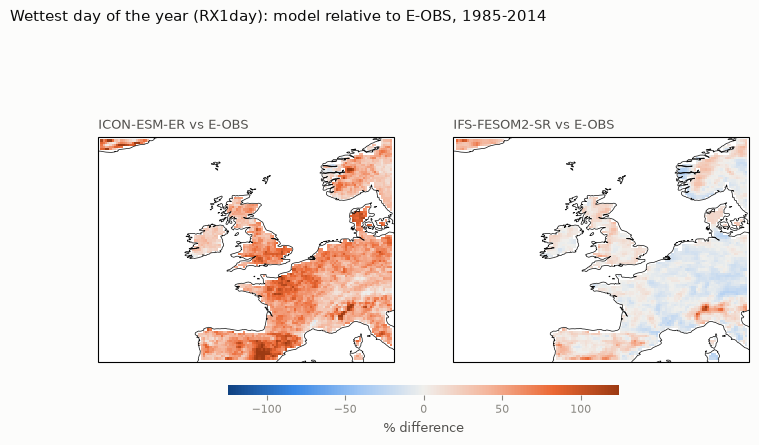

In [7]:
indices = {s: ex.indices_for(s) for s in ['e-obs'] + MODELS}
indices['e-obs'] = regions.to_grid(indices['e-obs'], indices['icon-esm-er'])
mean_rx = {s: indices[s].rx1day_ann.mean('year_ann') for s in indices}
plotting.plot_field_panels({f'{NAME[m]} vs E-OBS': 100 * (mean_rx[m] - mean_rx['e-obs']) / mean_rx['e-obs'] for m in MODELS},
                           units='% difference', diverging=True, title='Wettest day of the year (RX1day): model relative to E-OBS, 1985-2014');

**Figure 4.** Orange: the model's wettest day is wetter than in E-OBS. **IFS-FESOM2-SR is within
about 10%** over most of the region. **ICON-ESM-ER is roughly 50% too wet** almost everywhere.
Against ERA5 the excess is larger still (+60% and +17%). For the hottest day, ICON-ESM-ER is about
2 °C too cool against ERA5 as well as E-OBS. IFS-FESOM2-SR is only 0.6 °C cooler than ERA5, so most
of its 2 °C gap to E-OBS comes from comparing 25 km grid cells with low-lying stations.

## 5. Do the models link the NAO to extremes as the real world does? (notebook 06)

This is the centrepiece. In the real world, positive-NAO winters bring heavier rainfall extremes
to the north-west of Europe.

**What this cell does.** For the 29 winters 1986–2014, correlates winter very-wet-day rainfall
(R95p) with the winter NAO at every grid cell, after removing trends. E-OBS is paired with the
ERA5 NAO; each model with its own NAO. Dots mark cells that are statistically significant after
false-discovery-rate control.

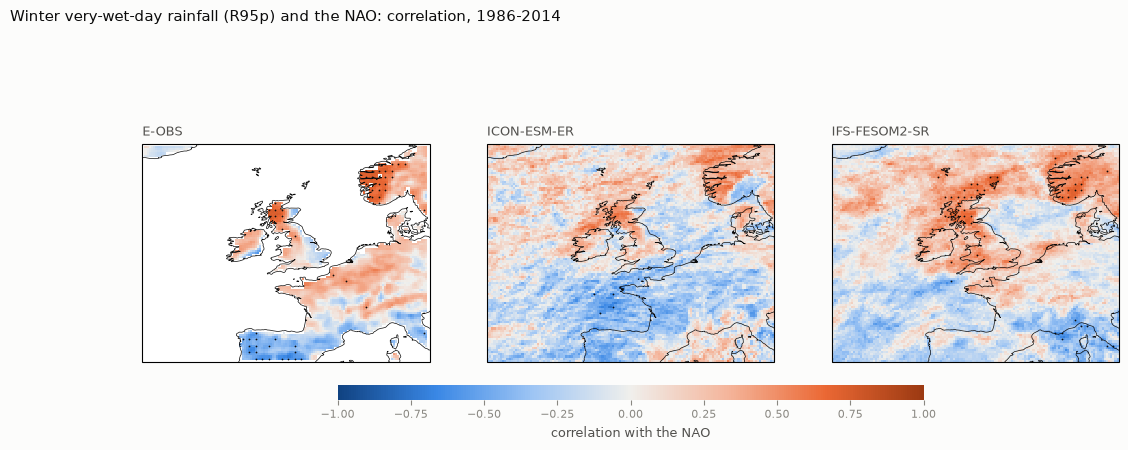

In [8]:
nao_table = pd.read_parquet('../app_assets/nao_index_winter.parquet')
def nao_index(source):
    rows = nao_table[(nao_table.source == source) & nao_table.year.between(1986, 2014)]
    return xr.DataArray(rows.nao_on_era5_pattern.values, coords={'year': rows.year.values}, dims='year')
results = {}
for d, source in (('e-obs', 'era5'), ('icon-esm-er', 'icon-esm-er'), ('ifs-fesom2-sr', 'ifs-fesom2-sr')):
    results[d] = rel.correlate(indices[d].r95p_djf.rename(year_djf='year'), nao_index(source))
plotting.plot_field_panels({NAME[d]: results[d].r for d in results}, units='correlation with the NAO', diverging=True, limit=1.0,
                           stipple={NAME[d]: rel.fdr_mask(results[d].p) for d in results},
                           title='Winter very-wet-day rainfall (R95p) and the NAO: correlation, 1986-2014');

**Figure 5.** Orange: more very-wet-day rain in positive-NAO winters; blue: less. E-OBS shows the
real-world pattern: a strong positive link over Scotland and Norway, negative over Iberia.
IFS-FESOM2-SR reproduces it. ICON-ESM-ER has the positive link in the north, but its negative
(dry) side reaches up across France.

**What this cell does.** The same link as numbers for UK and Ireland (land average): the
correlation with the NAO, the change per one standard deviation of NAO with its 95% range, and
the p value.

In [9]:
link = pd.read_parquet('../app_assets/nao_extremes_regional_link.parquet')
link[link.region == 'UK and Ireland'].drop(columns='region').set_index(['index', 'dataset'])

r  slope   low  high    p
index       dataset                                   
RX1day (mm) E-OBS         0.56   1.34  0.56  2.11 0.00
            ERA5          0.32   0.73 -0.12  1.57 0.10
            ICON-ESM-ER   0.28   1.63 -0.61  3.87 0.15
            IFS-FESOM2-SR 0.57   2.73  1.16  4.31 0.00
R95p (mm)   E-OBS         0.51  10.47  3.42 17.52 0.01
            ERA5          0.35   6.38 -0.41 13.17 0.07
            ICON-ESM-ER   0.36  17.30 -0.68 35.28 0.06
            IFS-FESOM2-SR 0.60  16.66  7.93 25.40 0.00
TXx (°C)    E-OBS         0.32   0.26 -0.05  0.57 0.10
            ERA5          0.31   0.25 -0.05  0.56 0.11
            ICON-ESM-ER   0.21   0.27 -0.21  0.75 0.27
            IFS-FESOM2-SR 0.12   0.12 -0.26  0.50 0.53

**Reading the table.** Where the range from `low` to `high` excludes zero, the link is
distinguishable from chance in 29 winters. The two references agree on the sign but not on the
strength over UK and Ireland: about 0.5 in E-OBS, about 0.33 in ERA5. **IFS-FESOM2-SR** (0.57 and
0.60) sits at the E-OBS end. **ICON-ESM-ER** (0.28 and 0.36) is close to ERA5 here, but it has the
wrong sign over north-west France and a weak link in western Norway. The mildest winter day (TXx)
has only a weak link over UK and Ireland in both references.

## 6. Is the NAO sensitive to small-scale sea-surface temperature? (notebook 07)

**What this cell does.** Uses the paired atmosphere-only experiments. For each of the ten members
of each experiment it measures the NAO strength (43 winters, 1981–2023) along the ERA5 pattern and
plots one dot per member.

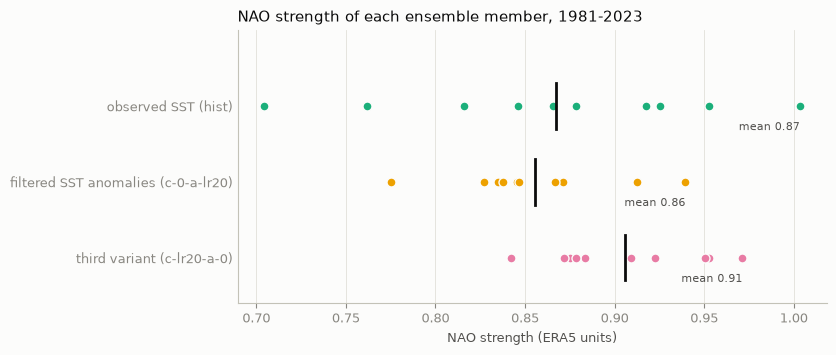

In [10]:
runs = ['hist', 'hist-c-0-a-lr20', 'hist-c-lr20-a-0']
strength = {}
for run in runs:
    w = nao.winter_anomalies(store.load(f'ifs-amip-tco399.{run}', 'mon', 'psl', 'north_atlantic'), (1980, 2023))
    strength[run] = (nao.project(w, eofs['era5'].vector) / eofs['era5'].amplitude).std('year', ddof=1).values
plotting.plot_member_dots(strength, xlabel='NAO strength (ERA5 units)', title='NAO strength of each ensemble member, 1981-2023');

**Figure 6.** Green: observed sea-surface temperature. Yellow and pink: two versions with the
small-scale detail filtered out. The three rows overlap almost completely: **filtering changes the
NAO strength by −1% and +4%, far less than the spread between members of one experiment.**
No sensitivity is detectable. This is an atmosphere-only test of sea-surface-temperature forcing;
it says nothing about a coupled effect of ocean eddies, and the exact filter is not verified.

## 7. Does higher resolution help? (notebook 08)

The cleanest test available: the **same** atmosphere model (IFS) with the **same** observed
sea-surface temperature, run at about 9 km and at about 28 km (three members), winters 1986–2014.

**What this cell does.** Averages the wettest winter day (RX1day) over the land of each region for
the two references, the 9 km run and each of the three 28 km members.

In [11]:
def winter_rx1day(source):
    daily = store.load(source, 'day', 'pr', 'nw_europe')
    daily = daily.sel(time=daily.time.dt.month.isin([12, 1, 2]))
    return ex.rx1day(daily, 'DJF').sel(year=slice(1986, 2014)).mean('year')
res = {'IFS 9 km': winter_rx1day('ifs-amip-tco1279.hist')}
lo = winter_rx1day('ifs-amip-tco399.hist')
res.update({f'IFS 28 km, member {int(m)}': lo.sel(realization=m) for m in lo.realization.values})
res['E-OBS'] = regions.to_grid(ex.indices_for('e-obs').rx1day_djf.mean('year_djf'), lo)
res['ERA5'] = ex.indices_for('era5').rx1day_djf.mean('year_djf')
land_cells = regions.land_mask(lo.lat, lo.lon) & res['E-OBS'].notnull()
pd.DataFrame({regions.LABELS[r]: {k: float(clim.regional_mean(v.where(land_cells), r)) for k, v in res.items()}
              for r in regions.SUBREGIONS}).round(1)

,UK and Ireland,Western Norway,North-west France
IFS 9 km,23.70,41.10,21.40
"IFS 28 km, member 1",22.90,36.60,20.20
"IFS 28 km, member 2",22.40,36.50,20.00
"IFS 28 km, member 3",22.50,37.30,21.60
E-OBS,21.90,39.30,20.90
ERA5,20.60,36.80,19.90


**Reading the table** (mm, wettest winter day, land average). At 9 km the wettest winter day is
5–12% heavier than at 28 km. Over western Norway, where 28 km falls short, that brings 9 km closer
to both references; over UK and Ireland, where 28 km is already about right, 9 km overshoots.
Across the whole region 9 km brings no overall improvement at the 25 km scale compared here.
The NAO-to-extremes correlation over UK and Ireland ranges from 0.04 to 0.33 between the three
identical 28 km runs, and 9 km (0.19) falls inside that range: **the conclusion depends more on
internal variability than on resolution.**

## 8. What weather brings the heaviest rain? (notebook 09)

**What this cell does.** Finds the 30 wettest winter days over UK and Ireland land in ERA5 and in
each model, and maps the average pressure anomaly on those days.

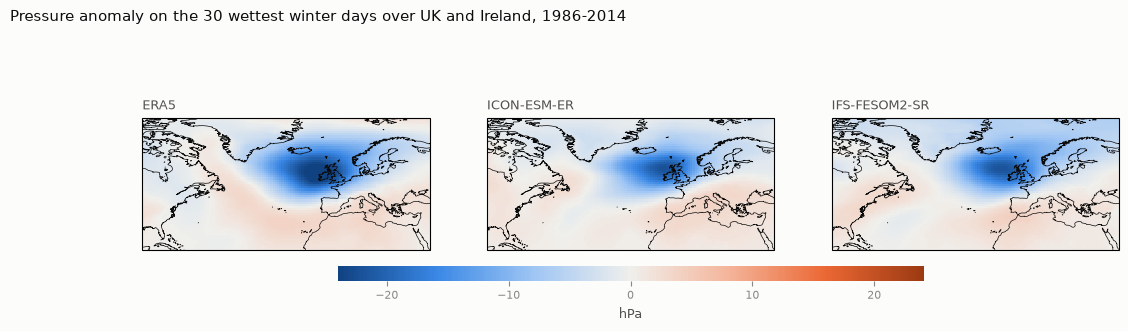

In [12]:
from eerie_uk import events as ev
def winter_days(da):
    da = da.sel(time=slice('1985-12-01', '2014-02-28'))
    return da.sel(time=da.time.dt.month.isin([12, 1, 2]))
composite = {}
for s in ['era5'] + MODELS:
    rain = winter_days(store.load(s, 'day', 'pr', 'nw_europe'))
    uk = clim.regional_mean(rain.where(land_cells), 'uk_ireland')
    pressure = winter_days(store.load(s, 'day', 'psl', 'north_atlantic'))
    composite[NAME[s]] = ev.lagged_composite(pressure - pressure.mean('time'), ev.top_events(uk, 30, 5), lags=(0,)).sel(lag=0)
plotting.plot_field_panels(composite, units='hPa', diverging=True,
                           title='Pressure anomaly on the 30 wettest winter days over UK and Ireland, 1986-2014');

**Figure 7.** In the real world (left) heavy UK winter rain comes with a deep low just north-west of
the islands and higher pressure to the south. **Both models produce their heaviest rain days
through the same weather** (pattern correlation 0.94–0.95 with ERA5). The difference is in the
build-up: two days earlier, IFS-FESOM2-SR's pattern still resembles ERA5's (0.85), ICON-ESM-ER's
much less (0.72). Both models also have a storm track 13–17% too active over the UK.

## 9. What was learned

| Step | ICON-ESM-ER | IFS-FESOM2-SR |
|---|---|---|
| Mean winter circulation | too-strong north–south pressure contrast | close to ERA5 |
| NAO pattern | mixed across two patterns | recognisable, southern centre weak |
| NAO strength | 0.59 of ERA5 | 0.71 of ERA5 |
| Rainfall extremes, UK and Ireland | 50–60% too heavy | within 10–20% of the references |
| Hottest day of the year | about 2 °C too cool against ERA5 | within 1 °C of ERA5 |
| NAO link to winter rainfall extremes | right sign, weak, misplaced boundary | reproduced in sign, pattern and strength |
| Weather behind the heaviest rain days | same pattern, weaker build-up | same pattern and build-up |
| Storm track over the UK | 17% too active | 13% too active |

1. **Each step depends on the one before.** ICON-ESM-ER's circulation bias shows up again as a wet
   bias, as a mean state that resembles a permanent positive NAO, as too-heavy rainfall extremes
   and as a misplaced NAO rainfall response. Checking the chain in order made that visible.
2. **A model can get the regional link right while its NAO is too weak.** IFS-FESOM2-SR reproduces
   how extremes respond to a given NAO swing, but produces smaller swings.
3. **Single members are a real limit.** The ensemble experiment shows that NAO strength ranges
   from 0.70 to 1.00 between ten identical runs. Several of the differences reported here are of that size.
4. **Higher resolution is not automatically better.** In IFS, 9 km gives heavier rain extremes,
   which helps over mountains and overshoots elsewhere; conclusions about the NAO's influence do
   not change with resolution but vary strongly between identical runs.
5. **Two good references can disagree.** E-OBS and ERA5 agree on patterns but not always on
   numbers (for example the strength of the NAO link over UK and Ireland), so "the observed
   value" itself carries uncertainty.
6. **In one atmosphere model, the seasonal NAO does not depend measurably on small-scale
   sea-surface temperature.**

## 10. Main limitations

- One member per coupled model; 64 winters for the NAO, 29 for the link to extremes.
- Two models: results are "consistent across the two models examined" at most.
- ERA5 is a reanalysis; its precipitation is a model product. E-OBS smooths intense rain and
  covers land only.
- Precipitation was regridded bilinearly, not conservatively.
- The decoding fix for IFS-FESOM2-SR data was checked against an older decoder and against the
  model's own monthly files, not against an independent tool.
- The paired experiment is atmosphere-only and its filter definition is unverified.
- The resolution comparison uses one 9 km run and three 28 km members, winter only, compared at 25 km.
- Model complexity and air quality are not tested.

## 11. What would come next

The analysis code takes any dataset that provides monthly sea-level pressure and daily
precipitation and maximum temperature under CMIP-style names. The same notebooks could therefore
be run on more EERIE members, on CMIP6 models, and on CMIP7 output when it becomes available.
Adding members is the single most valuable next step, because it would separate model behaviour
from chance. A natural extension is physical climate storylines: using the event composites of
notebook 09 to ask how a given type of heavy-rain winter would look under further warming, with
control runs to separate forced change from internal variability.

## Where to find the details

| Notebook | Content |
|---|---|
| `01_data_inventory` | what public EERIE data exist and can be read |
| `02_download_plan` | domains, datasets, periods, measured download cost |
| `03_validation_baseline` | data checks, mean climate and variability against ERA5 |
| `04_nao` | NAO pattern, index, strength, cross-checks |
| `05_extremes` | RX1day, TXx, R95p, annual and winter |
| `06_nao_extremes` | the NAO-to-extremes link |
| `07_paired_experiment` | NAO sensitivity to filtered sea-surface temperature |
| `08_resolution` | winter precipitation extremes at 9 km and 28 km |
| `09_event_anatomy` | the weather behind the heaviest winter rain days, storminess, persistent highs |

Methods: `docs/methods.md`. Code: `src/eerie_uk/`, with offline tests in `tests/`.